# Фаза 2 • Неделя 8 • Вторник
## Нейронные сети
### 🔥 PyTorch: Fashion MNIST

В этом задании необходимо классифицировать изображения датасета Fashion MNIST - аналогичного набору рукописных цифр. Для решения этой задачи не нужна сложная нейросеть, 

In [63]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor
import torchutils as tu
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['figure.dpi'] = 120
import pandas as pd

In [3]:
train_loader = DataLoader(
    FashionMNIST(
        root='data/', 
        train=True,
        download=True,
        transform=ToTensor()
    ),
    batch_size=64

)
valid_loader = DataLoader(
    FashionMNIST(
        root='data/', 
        train=False,
        download=True,
        transform=ToTensor()
    ),
    batch_size=64
)

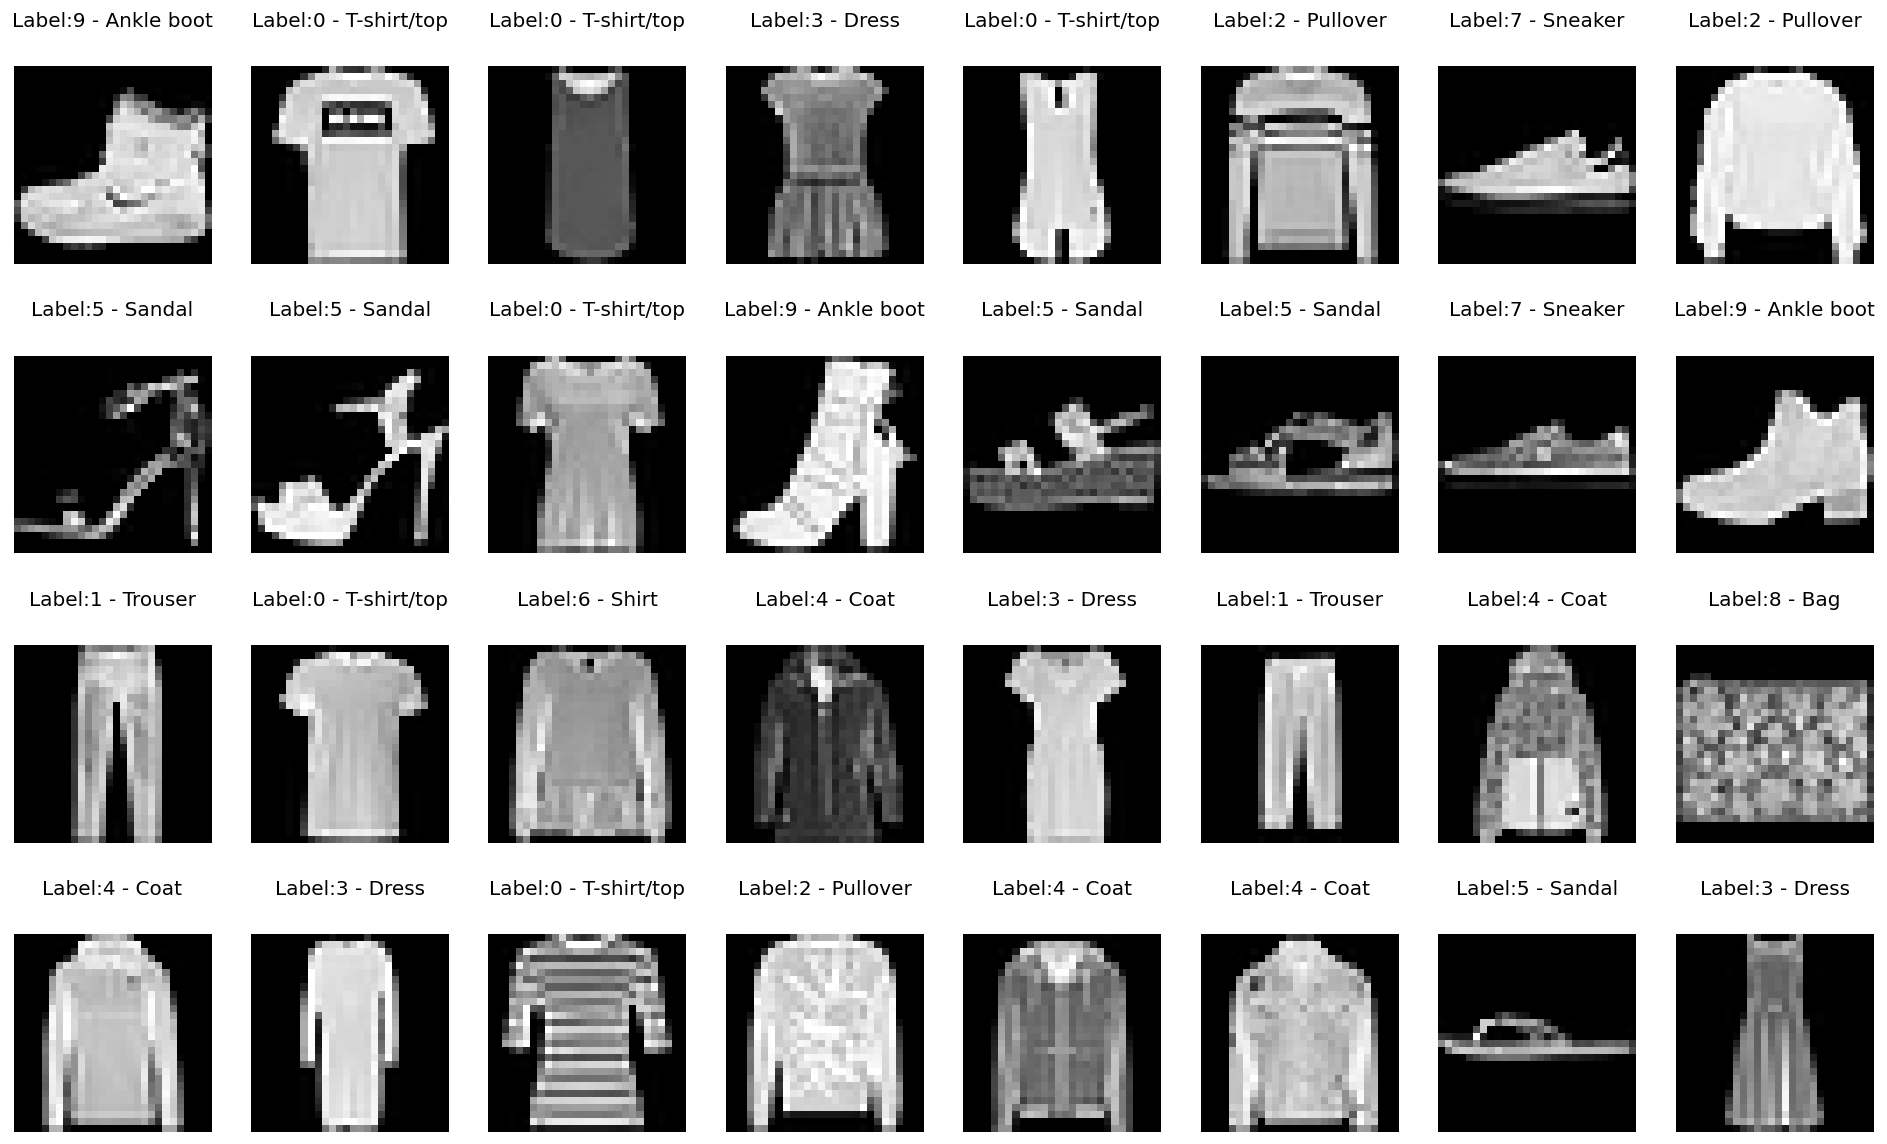

In [4]:
def get_batch_from_loader(loader):
    batch, labels = next(iter(loader))
    return batch, labels

# распечатаем произвольную картинку
fig, ax = plt.subplots(4, 8, figsize=(20, 12))
ax = ax.flatten()
batch, labels = get_batch_from_loader(train_loader)
for i, plot in enumerate(ax):
    plot.set_title(f'Label:{labels[i]} - {train_loader.dataset.classes[labels[i]]}')
    plot.matshow(batch[i][0, :, :], cmap='gray')
    plot.axis('off')

In [5]:
train_loader.dataset.classes
train_loader.dataset.class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

1. Задай класс модели: начни с самого простого однослойного персептрона. 

In [6]:
# Задаем класс модели
class TorchClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x_final = self.fc1(x)
        return x_final

2. С помощью `tu.get_model_summary` распечатай структуру модели

In [7]:
BATCH_SIZE = 64
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

In [8]:
model = TorchClassifier()
tu.get_model_summary(model, torch.randn(BATCH_SIZE, 1, 28, 28, device=DEVICE))

Layer    Kernel      Output    Params       FLOPs
0_fc1   [784, 10]   [64, 10]    7,850   1,002,880
Total params: 7,850
Trainable params: 7,850
Non-trainable params: 0
Total FLOPs: 1,002,880 / 1.00 MFLOPs
-------------------------------------------------
Input size (MB): 0.19
Forward/backward pass size (MB): 0.00
Params size (MB): 0.03
Estimated Total Size (MB): 0.23


In [9]:
list(model.parameters())

[Parameter containing:
 tensor([[ 0.0242,  0.0111, -0.0081,  ...,  0.0139,  0.0081, -0.0054],
         [ 0.0054,  0.0141,  0.0211,  ..., -0.0087, -0.0155, -0.0079],
         [-0.0219, -0.0191, -0.0311,  ..., -0.0032,  0.0184,  0.0156],
         ...,
         [-0.0015,  0.0126, -0.0344,  ...,  0.0076,  0.0187,  0.0020],
         [-0.0275,  0.0323, -0.0153,  ..., -0.0069, -0.0203,  0.0009],
         [ 0.0170, -0.0114, -0.0144,  ..., -0.0090, -0.0259,  0.0280]],
        requires_grad=True),
 Parameter containing:
 tensor([ 0.0014, -0.0107, -0.0270, -0.0006,  0.0290,  0.0011, -0.0043,  0.0337,
          0.0197, -0.0326], requires_grad=True)]

In [10]:
# batch, labels = get_batch_from_loader(train_loader)

In [11]:
# batch.shape

In [12]:
# labels.shape

3. Задай оптимизатор и функцию потерь

In [13]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
criterion = nn.CrossEntropyLoss()

4. Реализуй цикл обучения: функция должна возвращать историю лосса на обучении и валидации, а также значение метрики `accuracy`. 

In [14]:
def fit_model(epochs: int, model: nn.Module, optimizer: torch.optim.Optimizer) -> tuple[list, ...]:

    history = {
        'train_accs': [],
        'train_losses': [],
        'valid_accs': [],
        'valid_losses': [],
    }

    for i in range(epochs):

        model.train()
        train_loss = []
        valid_loss = []
        train_metric = []
        valid_metric = [] 
    
        for data, labels in train_loader:
            data = data.to(DEVICE)
            labels = labels.to(DEVICE)

            y_pred = model(data)
            loss = criterion(y_pred, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss.append(loss.item())
            train_metric.append((y_pred.argmax(axis=1) == labels).cpu().numpy().mean())

        history['train_losses'].append(np.mean(train_loss))
        history['train_accs'].append(np.mean(train_metric))

        model.eval()
        for data, labels in valid_loader:
            with torch.no_grad():
                y_pred = model(data.to(DEVICE))
                loss = criterion(y_pred, labels.to(DEVICE))

                valid_loss.append(loss.item())
                valid_metric.append((y_pred.cpu().argmax(axis=1) == labels.cpu()).numpy().mean())

        history['valid_accs'].append(np.mean(valid_metric))
        history['valid_losses'].append(np.mean(valid_loss))

        print(
            f'train: accuracy {history["train_accs"][-1]:.4f}, loss {history["train_losses"][-1]:.4f}\n'
            f'valid: accuracy {history["valid_accs"][-1]:.4f}, loss {history["valid_losses"][-1]:.4f}'
        )
        print(f'{"-"*35}')
        print()

    # return train_loss, valid_loss, train_metric, valid_metric
    return history

In [15]:
history = fit_model(epochs=5, model=model, optimizer=optimizer)

train: accuracy 0.8139, loss 0.5402
valid: accuracy 0.8235, loss 0.5234
-----------------------------------

train: accuracy 0.8418, loss 0.4554
valid: accuracy 0.8293, loss 0.5130
-----------------------------------

train: accuracy 0.8483, loss 0.4397
valid: accuracy 0.8303, loss 0.5117
-----------------------------------

train: accuracy 0.8510, loss 0.4310
valid: accuracy 0.8317, loss 0.5118
-----------------------------------

train: accuracy 0.8530, loss 0.4251
valid: accuracy 0.8317, loss 0.5121
-----------------------------------



Построй кривые обучения: функции потерь и метрики на обучении и валидации

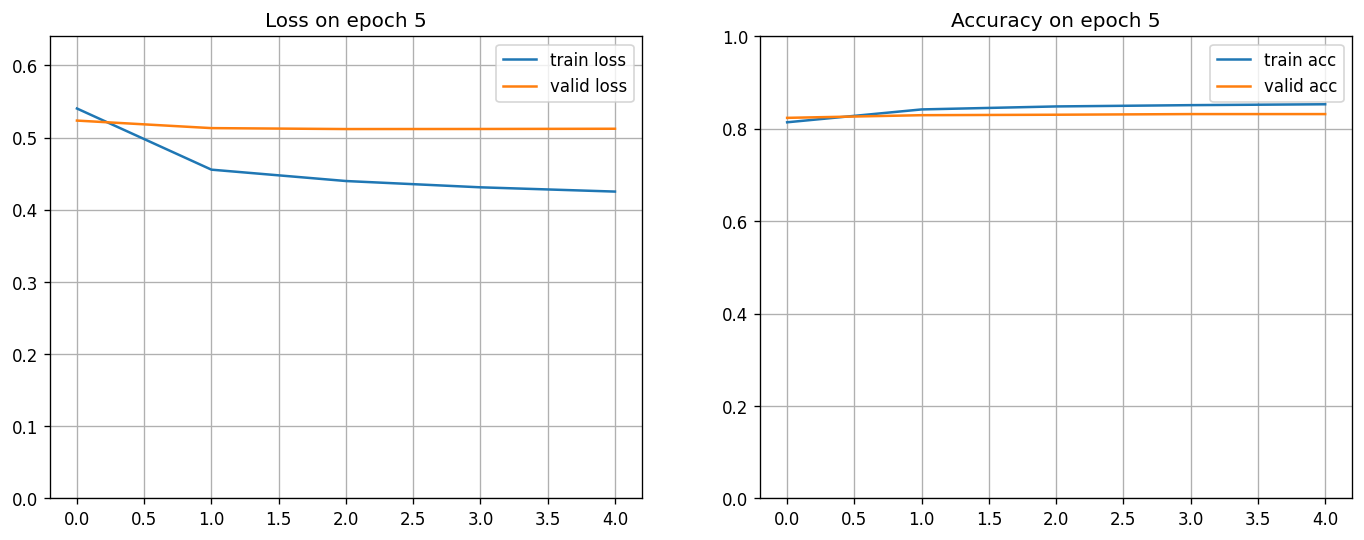

In [16]:
fig, ax = plt.subplots(1,2, figsize=(14,5))
    
ax[0].plot(history['train_losses'], label='train loss')
ax[0].plot(history['valid_losses'], label='valid loss')
ax[0].set_title(f'Loss on epoch {len(history["train_losses"])}')
ax[0].grid(True)
ax[0].set_ylim((0, max(history['train_losses'] + history['valid_losses'])+.1))
ax[0].legend()
    
ax[1].plot(history['train_accs'], label='train acc')
ax[1].plot(history['valid_accs'], label='valid acc')
ax[1].set_title(f'Accuracy on epoch {len(history["train_losses"])}')
ax[1].grid(True)
ax[1].set_ylim((0, 1))
ax[1].legend()
    
plt.show()

5. Попробуй создать еще 2 модели с разной архитектурой и проанализируй качество их решений. Для этого распечатай графики лосса и метрики на выборках. На что повлияло число нейронов и слоев? 

    ❗️ Самые сложные модели должны достигать качества >80% на валидационной части выборки.

    ❗️ При создании новой модели **обязательно** нужно создать новый оптимизатор, в который будут передаваться параметры новой модели. 

In [17]:
BATCH_SIZE=64
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

In [18]:
def plot_history(history, grid=True):
    fig, ax = plt.subplots(1,2, figsize=(14,5))
    
    ax[0].plot(history['train_losses'], label='train loss')
    ax[0].plot(history['valid_losses'], label='valid loss')
    ax[0].set_title(f'Loss on epoch {len(history["train_losses"])}')
    ax[0].grid(grid)
    ax[0].set_ylim((0, max(history['train_losses'] + history['valid_losses'])+.1))
    ax[0].legend()
    
    ax[1].plot(history['train_accs'], label='train acc')
    ax[1].plot(history['valid_accs'], label='valid acc')
    ax[1].set_title(f'Accuracy on epoch {len(history["train_losses"])}')
    ax[1].grid(grid)
    ax[1].set_ylim((0, 1))
    ax[1].legend()
    
    plt.show()

МОДЕЛЬ 2

In [19]:
# Задаем класс модели
class TorchClassifier2(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 32)
        self.bn3 = nn.BatchNorm1d(32)
        self.fc4 = nn.Linear(32, 10)
        self.dropout = nn.Dropout()

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x_1 = F.relu(self.fc1(x))
        x_2 = F.sigmoid(self.fc2(x_1))
        x_3 = self.dropout(F.relu(self.bn3(self.fc3(x_2))))
        x_final = self.fc4(x_3)
        return x_final

In [20]:
model_2 = TorchClassifier2()
tu.get_model_summary(model_2, torch.randn(BATCH_SIZE, 1, 28, 28, device=DEVICE))

Layer         Kernel      Output     Params         FLOPs
0_fc1       [784, 128]   [64, 128]   100,480   12,836,864
1_fc2        [128, 64]    [64, 64]     8,256    1,044,480
2_fc3         [64, 32]    [64, 32]     2,080      260,096
3_bn3             [32]    [64, 32]        64        8,192
4_dropout            -    [64, 32]         0            0
5_fc4         [32, 10]    [64, 10]       330       40,320
Total params: 111,210
Trainable params: 111,210
Non-trainable params: 0
Total FLOPs: 14,189,952 / 14.19 MFLOPs
---------------------------------------------------------
Input size (MB): 0.19
Forward/backward pass size (MB): 0.15
Params size (MB): 0.42
Estimated Total Size (MB): 0.76


In [21]:
optimizer = torch.optim.Adam(model_2.parameters(), lr=0.005)
criterion = nn.CrossEntropyLoss()

In [22]:
def fit_model(epochs: int, model: nn.Module, optimizer: torch.optim.Optimizer) -> tuple[list, ...]:

    history = {
        'train_accs': [],
        'train_losses': [],
        'valid_accs': [],
        'valid_losses': [],
    }

    for i in range(epochs):

        model.train()
        train_loss = []
        valid_loss = []
        train_metric = []
        valid_metric = [] 
    
        for data, labels in train_loader:
            data = data.to(DEVICE)
            labels = labels.to(DEVICE)

            y_pred = model(data)
            loss = criterion(y_pred, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss.append(loss.item())
            train_metric.append((y_pred.argmax(axis=1) == labels).cpu().numpy().mean())

        history['train_losses'].append(np.mean(train_loss))
        history['train_accs'].append(np.mean(train_metric))

        model.eval()
        for data, labels in valid_loader:
            with torch.no_grad():
                y_pred = model(data.to(DEVICE))
                loss = criterion(y_pred, labels.to(DEVICE))

                valid_loss.append(loss.item())
                valid_metric.append((y_pred.cpu().argmax(axis=1) == labels.cpu()).numpy().mean())

        history['valid_accs'].append(np.mean(valid_metric))
        history['valid_losses'].append(np.mean(valid_loss))

        print(
            f'train: accuracy {history["train_accs"][-1]:.4f}, loss {history["train_losses"][-1]:.4f}\n'
            f'valid: accuracy {history["valid_accs"][-1]:.4f}, loss {history["valid_losses"][-1]:.4f}'
        )
        print(f'{"-"*35}')

    plot_history(history)
    
    return history

train: accuracy 0.7738, loss 0.6673
valid: accuracy 0.8124, loss 0.5039
-----------------------------------
train: accuracy 0.8293, loss 0.5098
valid: accuracy 0.8470, loss 0.4182
-----------------------------------
train: accuracy 0.8418, loss 0.4678
valid: accuracy 0.8546, loss 0.4094
-----------------------------------
train: accuracy 0.8468, loss 0.4435
valid: accuracy 0.8505, loss 0.4173
-----------------------------------
train: accuracy 0.8527, loss 0.4259
valid: accuracy 0.8578, loss 0.4019
-----------------------------------
train: accuracy 0.8557, loss 0.4125
valid: accuracy 0.8594, loss 0.3844
-----------------------------------
train: accuracy 0.8592, loss 0.4008
valid: accuracy 0.8557, loss 0.3940
-----------------------------------
train: accuracy 0.8641, loss 0.3892
valid: accuracy 0.8671, loss 0.4001
-----------------------------------
train: accuracy 0.8632, loss 0.3875
valid: accuracy 0.8642, loss 0.4248
-----------------------------------
train: accuracy 0.8666, loss

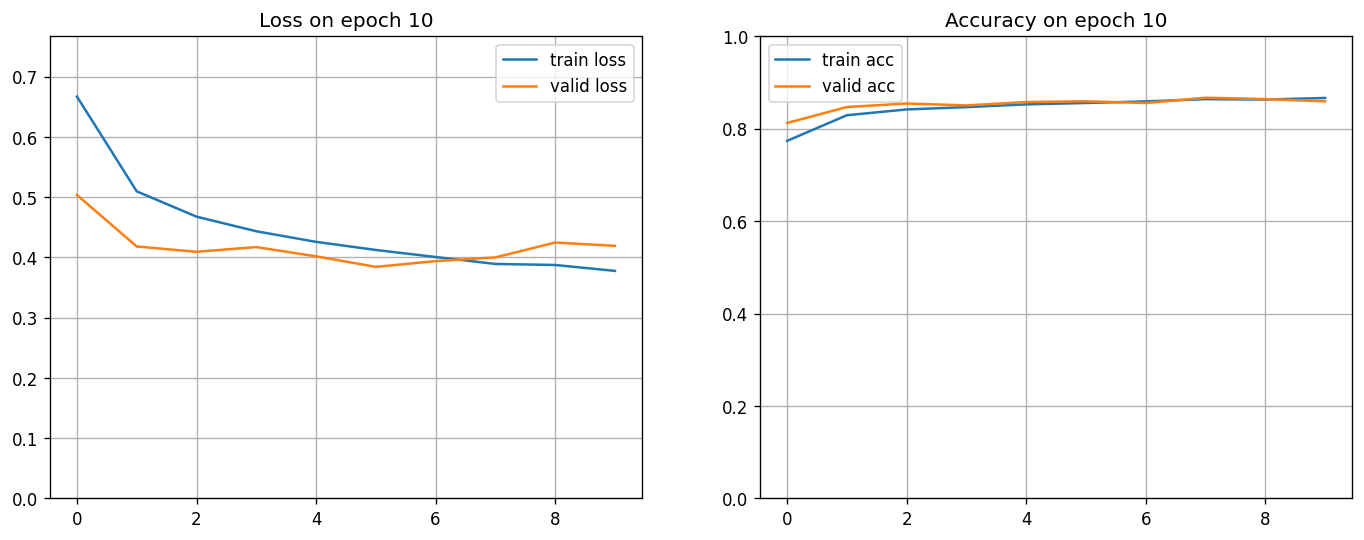

In [23]:
history_2 = fit_model(10, model_2, optimizer)

In [24]:
print(f'Первая модель: {history["valid_accs"][-1] * 100:.2f}%')
print(f'Вторая модель: {history_2["valid_accs"][-1] * 100:.2f}%')

Первая модель: 83.17%
Вторая модель: 85.94%


МОДЕЛЬ 3

In [36]:
# Задаем класс модели
class TorchClassifier3(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1) # свёрточный слой нейросети, 
        # помогает модели находить особенности на изображении
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(1568, 128)
        self.fc2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64) # берёт каждый из 64 признаков и нормализует его значение по всем (64) изображениям батча
        self.fc3 = nn.Linear(64, 32)
        self.bn3 = nn.BatchNorm1d(32)
        self.fc4 = nn.Linear(32, 10)
        self.dropout = nn.Dropout()
        self.pool = nn.MaxPool2d(2, 2) # уменьшает размер 

    def forward(self, x):
        x_1 = F.relu(self.conv1(x))
        x_2 = self.pool(x_1)
        x_3 = F.relu(self.conv2(x_2))
        x_4 = self.pool(x_3)
        x_5 = x_4.view(x_4.size(0), -1)
        x_6 = F.relu(self.fc1(x_5))
        x_7 = F.relu(self.bn2(self.fc2(x_6)))
        x_8 = self.dropout(F.relu(self.bn3(self.fc3(x_7))))
        x_final = self.fc4(x_8)
        return x_final

In [37]:
model_3 = TorchClassifier3()
tu.get_model_summary(model_3, torch.randn(BATCH_SIZE, 1, 28, 28, device=DEVICE))

Layer           Kernel            Output        Params         FLOPs
0_conv1      [1, 16, 3, 3]   [64, 16, 28, 28]       160    8,028,160
1_pool                   -   [64, 16, 14, 14]         0            0
2_conv2     [16, 32, 3, 3]   [64, 32, 14, 14]     4,640   58,204,160
3_pool                   -     [64, 32, 7, 7]         0            0
4_fc1          [1568, 128]          [64, 128]   200,832   25,681,920
5_fc2            [128, 64]           [64, 64]     8,256    1,044,480
6_bn2                 [64]           [64, 64]       128       16,384
7_fc3             [64, 32]           [64, 32]     2,080      260,096
8_bn3                 [32]           [64, 32]        64        8,192
9_dropout                -           [64, 32]         0            0
10_fc4            [32, 10]           [64, 10]       330       40,320
Total params: 216,490
Trainable params: 216,490
Non-trainable params: 0
Total FLOPs: 93,283,712 / 93.28 MFLOPs
-------------------------------------------------------------

In [38]:
optimizer = torch.optim.Adam(model_3.parameters(), lr=0.005)
criterion = nn.CrossEntropyLoss()

train: accuracy 0.8104, loss 0.5760
valid: accuracy 0.8191, loss 0.4532
-----------------------------------
train: accuracy 0.8658, loss 0.4045
valid: accuracy 0.8900, loss 0.3085
-----------------------------------
train: accuracy 0.8772, loss 0.3657
valid: accuracy 0.8793, loss 0.3469
-----------------------------------
train: accuracy 0.8867, loss 0.3395
valid: accuracy 0.8960, loss 0.2959
-----------------------------------
train: accuracy 0.8921, loss 0.3218
valid: accuracy 0.8901, loss 0.3104
-----------------------------------
train: accuracy 0.8948, loss 0.3087
valid: accuracy 0.8965, loss 0.3008
-----------------------------------
train: accuracy 0.8983, loss 0.2947
valid: accuracy 0.9055, loss 0.2730
-----------------------------------
train: accuracy 0.9023, loss 0.2852
valid: accuracy 0.9013, loss 0.2911
-----------------------------------
train: accuracy 0.9043, loss 0.2737
valid: accuracy 0.9038, loss 0.2814
-----------------------------------
train: accuracy 0.9083, loss

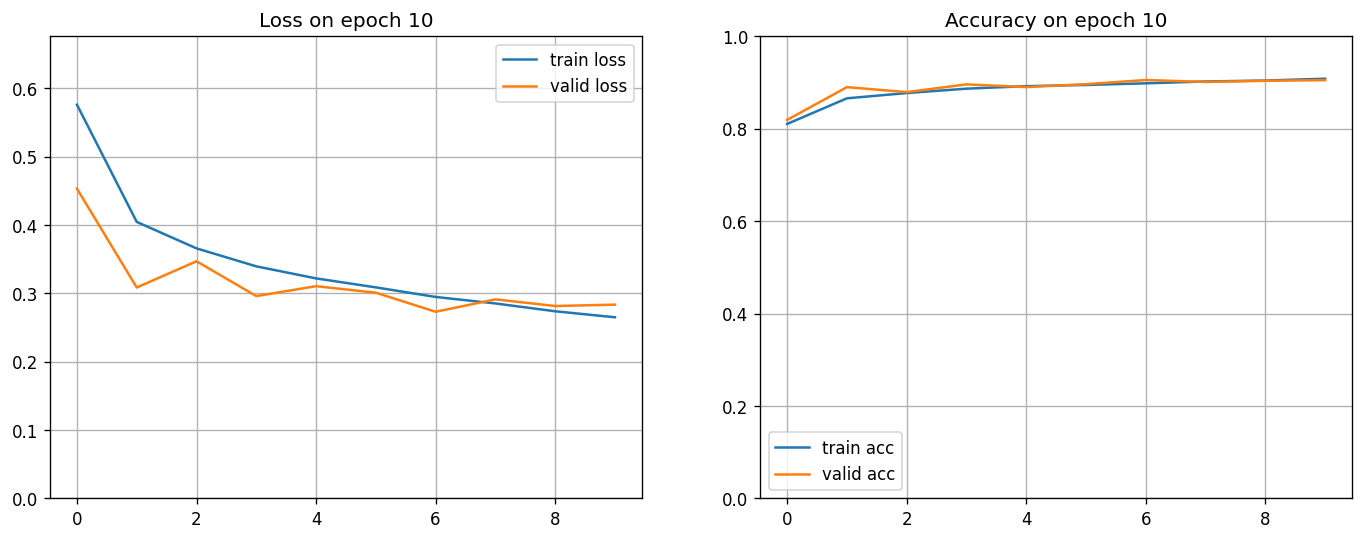

In [39]:
history_3 = fit_model(10, model_3, optimizer)

In [26]:
# исходное изображение 64х1х28х28
# после первого Conv2d = 16*28*28 - было 1 канал, стало 16 nn.Conv2d(1, 16,...
# после первого MaxPool2d (уменьшает ширину и высоту в два раза 28/2 = 14) = 16*14*14
# после второго Conv2d = 32*14*14
# после вторго MaxPool2d = 32*7*7

In [27]:
32*7*7

1568

In [28]:
conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
pool = nn.MaxPool2d(2, 2)

x = torch.randn(64, 1, 28, 28)

x = pool(conv1(x))
x = pool(conv2(x))

n_features = x[0].numel()

print(n_features)

1568


In [34]:
# проверить слой отдельно от класса
conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
conv1

Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

In [30]:
# проверка размера батча
data, labels = next(iter(train_loader))
print(data.shape)

torch.Size([64, 1, 28, 28])


In [40]:
print(f'Первая модель: {history["valid_accs"][-1] * 100:.2f}%')
print(f'Вторая модель: {history_2["valid_accs"][-1] * 100:.2f}%')
print(f'Третья модель: {history_3["valid_accs"][-1] * 100:.2f}%')

Первая модель: 83.17%
Вторая модель: 85.94%
Третья модель: 90.52%


# ❓

Для чего при обучении применяется слой `Dropout`?

для борьбы с переобучением (переобучение это когда модель сильно опирается на трейдовые данные (танк и галочка))
случайным образом откючает нейроны, что позволяет равномерно распределять информацию между нейронами (где-то модель сильно
опиралась на нейрон, его отключили, модель ищет другую зависимость)

6. Обучи лучшую модель 3 раза с тремя разными оптимизаторами: `SGD`, `Adagrad`, `Adadelta`. Визуализируй график лосса и сравни, как изменяется значение функции потерь в зависимости от используемого алгоритма оптимизации. Какой алгоритм самый лучший?

В результате должен получиться **примерно** такой график: 

![](aux/imgs/08-02-res.png)

In [46]:
import copy

model_best = TorchClassifier3().to(DEVICE)

weights = copy.deepcopy(model_best.state_dict())
# model_base.state_dict() — возвращает словарь со всеми параметрами модели: весами и смещениями (bias), а также состоянием BatchNorm.

SGD

train: accuracy 0.7481, loss 0.9157
valid: accuracy 0.8187, loss 0.5844
-----------------------------------
train: accuracy 0.8265, loss 0.5801
valid: accuracy 0.8172, loss 0.4755
-----------------------------------
train: accuracy 0.8482, loss 0.4958
valid: accuracy 0.8244, loss 0.4649
-----------------------------------
train: accuracy 0.8607, loss 0.4542
valid: accuracy 0.8567, loss 0.3828
-----------------------------------
train: accuracy 0.8704, loss 0.4206
valid: accuracy 0.8312, loss 0.4471
-----------------------------------
train: accuracy 0.8779, loss 0.3952
valid: accuracy 0.8829, loss 0.3309
-----------------------------------
train: accuracy 0.8853, loss 0.3757
valid: accuracy 0.8835, loss 0.3264
-----------------------------------
train: accuracy 0.8888, loss 0.3585
valid: accuracy 0.8120, loss 0.5187
-----------------------------------
train: accuracy 0.8947, loss 0.3413
valid: accuracy 0.8558, loss 0.4050
-----------------------------------
train: accuracy 0.8972, loss

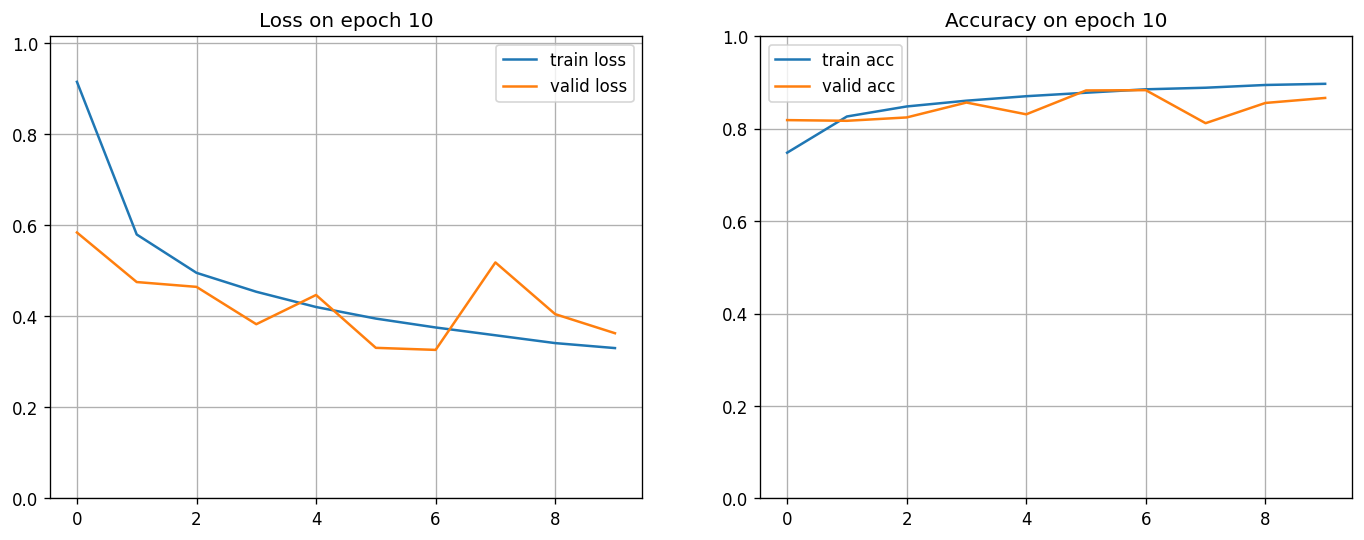

In [48]:
model_sgd = TorchClassifier3().to(DEVICE)
model_sgd.load_state_dict(weights)
# state_dict() — достаёт параметры из модели
# load_state_dict() — загружает параметры в модель

optimizer_sgd = torch.optim.SGD(model_sgd.parameters(), lr=0.01)
history_sgd = fit_model(10, model_sgd, optimizer_sgd)

Adagrad

train: accuracy 0.8145, loss 0.6261
valid: accuracy 0.8882, loss 0.3248
-----------------------------------
train: accuracy 0.8695, loss 0.4196
valid: accuracy 0.8965, loss 0.2892
-----------------------------------
train: accuracy 0.8838, loss 0.3716
valid: accuracy 0.9009, loss 0.2764
-----------------------------------
train: accuracy 0.8910, loss 0.3421
valid: accuracy 0.8964, loss 0.2879
-----------------------------------
train: accuracy 0.8985, loss 0.3207
valid: accuracy 0.9050, loss 0.2653
-----------------------------------
train: accuracy 0.9022, loss 0.3056
valid: accuracy 0.9077, loss 0.2601
-----------------------------------
train: accuracy 0.9086, loss 0.2875
valid: accuracy 0.9061, loss 0.2578
-----------------------------------
train: accuracy 0.9111, loss 0.2769
valid: accuracy 0.9073, loss 0.2614
-----------------------------------
train: accuracy 0.9143, loss 0.2673
valid: accuracy 0.9087, loss 0.2589
-----------------------------------
train: accuracy 0.9174, loss

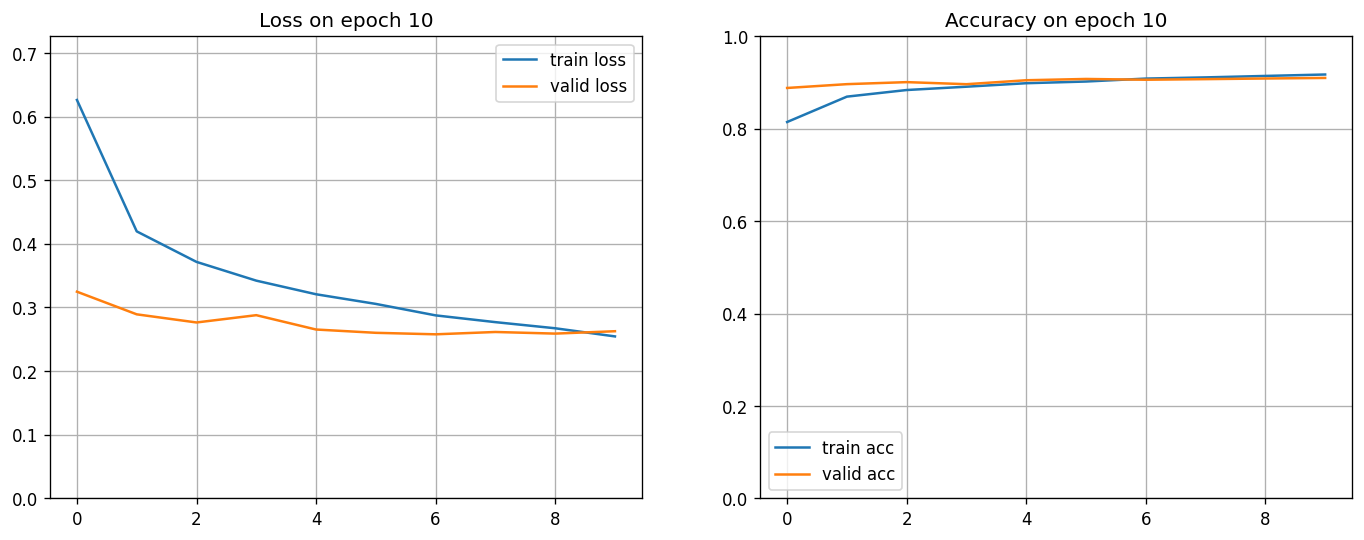

In [49]:
model_adagrad = TorchClassifier3().to(DEVICE)
model_adagrad.load_state_dict(weights)

optimizer_adagrad = torch.optim.Adagrad(model_adagrad.parameters(), lr=0.01)
history_adagrad = fit_model(10, model_adagrad, optimizer_adagrad)

Adadelta

train: accuracy 0.8085, loss 0.5822
valid: accuracy 0.8604, loss 0.3932
-----------------------------------
train: accuracy 0.8679, loss 0.4014
valid: accuracy 0.8854, loss 0.3232
-----------------------------------
train: accuracy 0.8804, loss 0.3561
valid: accuracy 0.8938, loss 0.3100
-----------------------------------
train: accuracy 0.8890, loss 0.3336
valid: accuracy 0.8882, loss 0.3351
-----------------------------------
train: accuracy 0.8951, loss 0.3096
valid: accuracy 0.9023, loss 0.2978
-----------------------------------
train: accuracy 0.9002, loss 0.2979
valid: accuracy 0.9034, loss 0.2832
-----------------------------------
train: accuracy 0.9049, loss 0.2820
valid: accuracy 0.9026, loss 0.3199
-----------------------------------
train: accuracy 0.9069, loss 0.2694
valid: accuracy 0.8953, loss 0.3380
-----------------------------------
train: accuracy 0.9101, loss 0.2594
valid: accuracy 0.9062, loss 0.2898
-----------------------------------
train: accuracy 0.9128, loss

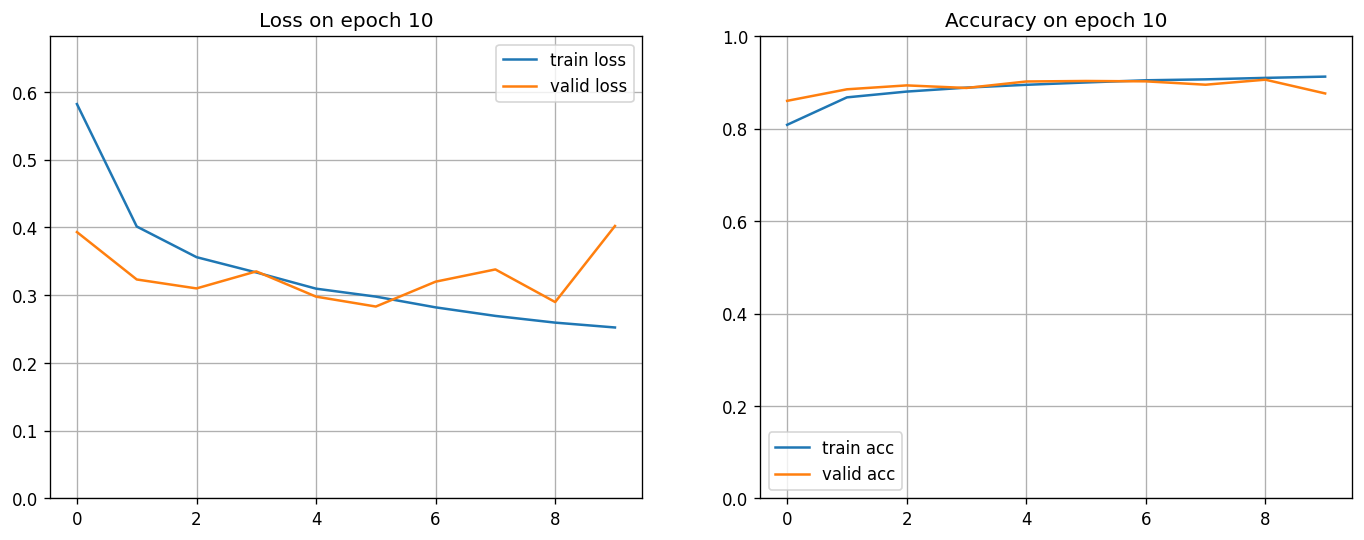

In [50]:
model_adadelta = TorchClassifier3().to(DEVICE)
model_adadelta.load_state_dict(weights)

optimizer_adadelta = torch.optim.Adadelta(model_adadelta.parameters())
history_adadelta = fit_model(10, model_adadelta, optimizer_adadelta)

Построим общий график Loss

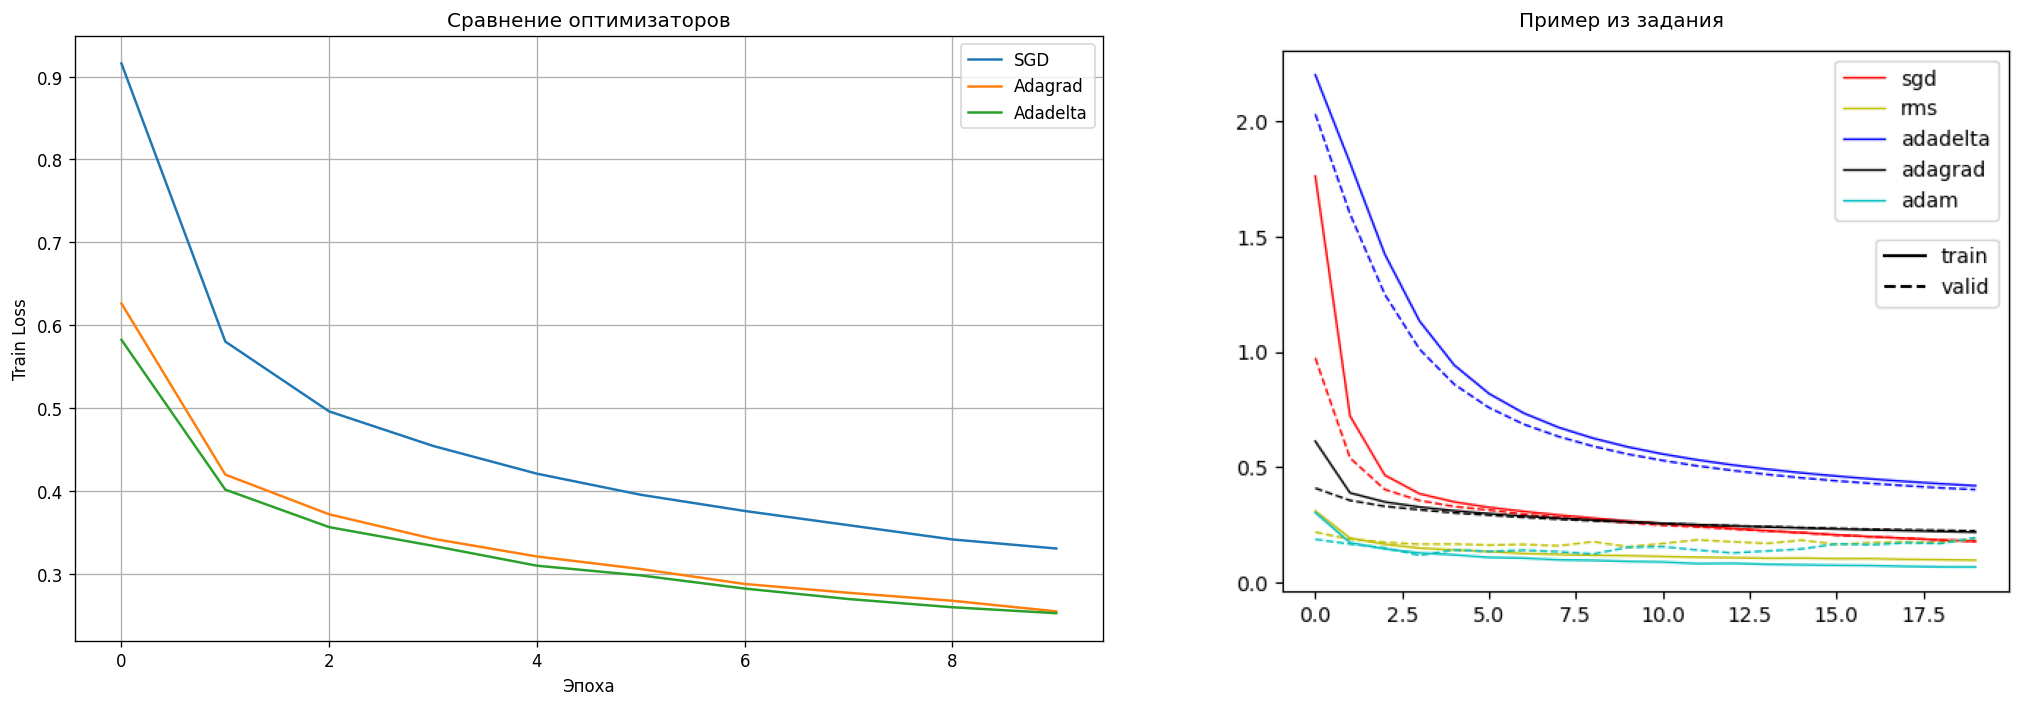

In [53]:
from PIL import Image
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# Слева — наши результаты
ax[0].plot(history_sgd['train_losses'], label='SGD')
ax[0].plot(history_adagrad['train_losses'], label='Adagrad')
ax[0].plot(history_adadelta['train_losses'], label='Adadelta')

ax[0].set_title('Сравнение оптимизаторов')
ax[0].set_xlabel('Эпоха')
ax[0].set_ylabel('Train Loss')
ax[0].legend()
ax[0].grid()

# Справа — пример из задания
img = Image.open('08-02-res.png')
ax[1].imshow(img)
ax[1].set_title('Пример из задания')
ax[1].axis('off')

plt.tight_layout()
plt.show()

### 🎓 Реализуй архитектуру, представленную ниже, и сравни ее эффективность с обученными выше моделями. 
Такое можно сделать только с помощью разработки класса модели, обычный sequential-подход тут не поможет. 


<img src="aux/imgs/simple_skip_con.png" height=500>

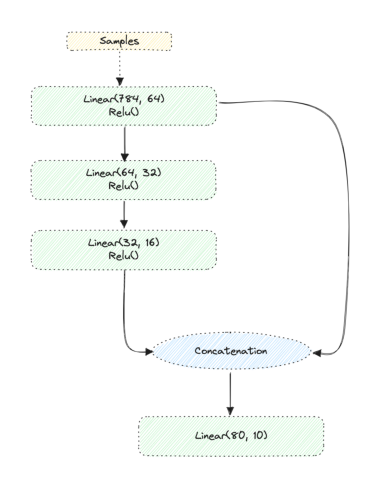

In [44]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open('simple_skip_con.png')

plt.figure(figsize=(10, 5))
plt.imshow(img)
plt.axis('off');

In [56]:
class TorchClassifier4(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 16)
        self.fc4 = nn.Linear(80, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x_1 = F.relu(self.fc1(x))
        x_2 = F.relu(self.fc2(x_1))
        x_3 = F.relu(self.fc3(x_2))

        x_concat = torch.cat((x_1, x_3), dim=1) # concatenate - соединять
        # torch.cat - объединяет тензоры (многомерный массив)
        # x_1 имеет форму [64, 64]
        # x_3 имеет форму [64, 16]
        # dim=1 означает объединение по столбцам, то есть по признакам
        
        x_final = self.fc4(x_concat)

        return x_final

x = torch.randn(64, 1, 28, 28) 
 
Это тензор с четырьмя измерениями:
- 64 — количество изображений;
- 1 — количество каналов (изображения чёрно-белые);
- 28 — высота;
- 28 — ширина.

In [55]:
# посмотреть форму тензора
print(x.shape)
print(x.ndim)

torch.Size([64, 32, 7, 7])
4


In [57]:
model_4 = TorchClassifier4().to(DEVICE)

tu.get_model_summary(
    model_4,
    torch.randn(BATCH_SIZE, 1, 28, 28, device=DEVICE)
)

Layer    Kernel      Output    Params       FLOPs
0_fc1   [784, 64]   [64, 64]   50,240   6,418,432
1_fc2    [64, 32]   [64, 32]    2,080     260,096
2_fc3    [32, 16]   [64, 16]      528      64,512
3_fc4    [80, 10]   [64, 10]      810     101,760
Total params: 53,658
Trainable params: 53,658
Non-trainable params: 0
Total FLOPs: 6,844,800 / 6.84 MFLOPs
-------------------------------------------------
Input size (MB): 0.19
Forward/backward pass size (MB): 0.06
Params size (MB): 0.20
Estimated Total Size (MB): 0.46


train: accuracy 0.8171, loss 0.5057
valid: accuracy 0.8460, loss 0.4284
-----------------------------------
train: accuracy 0.8588, loss 0.3853
valid: accuracy 0.8533, loss 0.4130
-----------------------------------
train: accuracy 0.8691, loss 0.3564
valid: accuracy 0.8576, loss 0.4040
-----------------------------------
train: accuracy 0.8755, loss 0.3391
valid: accuracy 0.8549, loss 0.3987
-----------------------------------
train: accuracy 0.8803, loss 0.3248
valid: accuracy 0.8623, loss 0.3921
-----------------------------------
train: accuracy 0.8831, loss 0.3148
valid: accuracy 0.8531, loss 0.4239
-----------------------------------
train: accuracy 0.8868, loss 0.3057
valid: accuracy 0.8582, loss 0.4090
-----------------------------------
train: accuracy 0.8881, loss 0.2996
valid: accuracy 0.8659, loss 0.3925
-----------------------------------
train: accuracy 0.8915, loss 0.2905
valid: accuracy 0.8626, loss 0.4034
-----------------------------------
train: accuracy 0.8943, loss

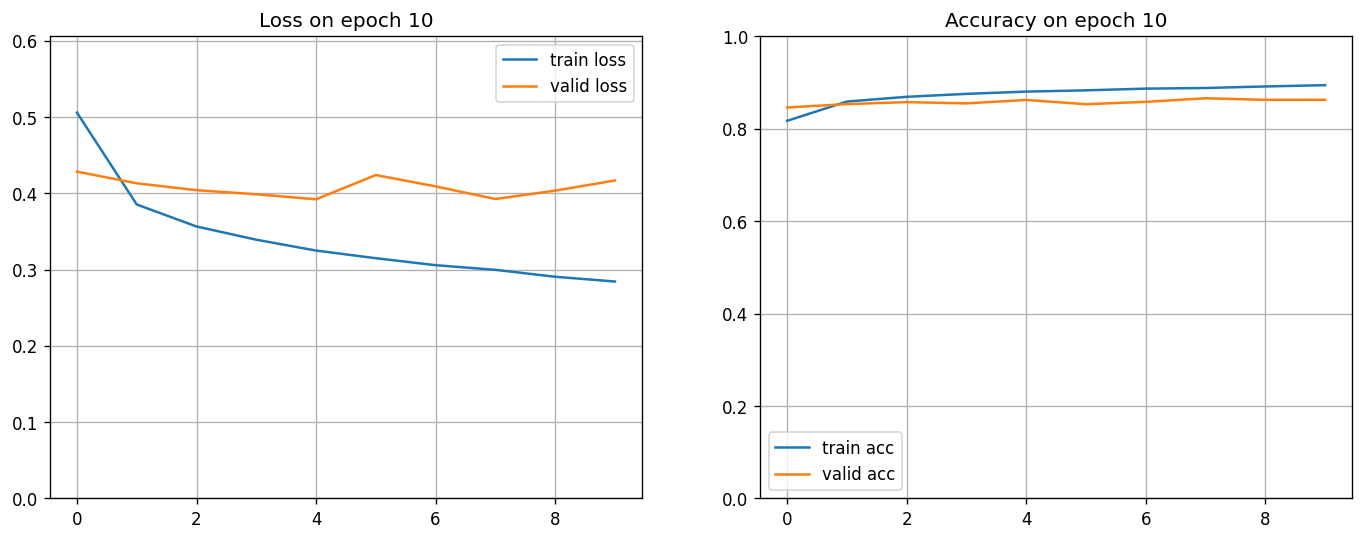

In [58]:
model_4 = TorchClassifier4().to(DEVICE)

optimizer_4 = torch.optim.Adam(model_4.parameters(), lr=0.005)

history_4 = fit_model(10, model_4, optimizer_4)

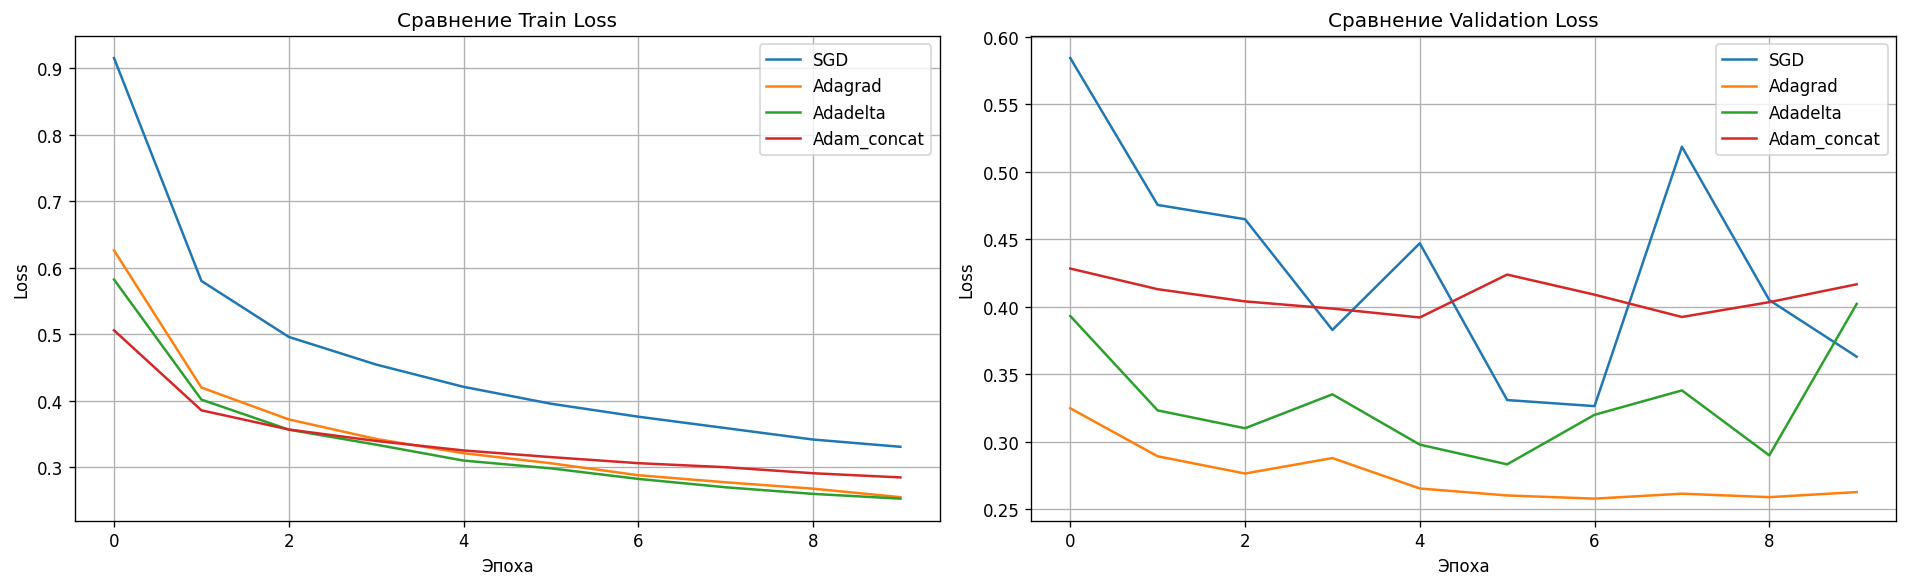

In [61]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Train Loss
ax[0].plot(history_sgd['train_losses'], label='SGD')
ax[0].plot(history_adagrad['train_losses'], label='Adagrad')
ax[0].plot(history_adadelta['train_losses'], label='Adadelta')
ax[0].plot(history_4['train_losses'], label='Adam_concat')

ax[0].set_title('Сравнение Train Loss')
ax[0].set_xlabel('Эпоха')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid()

# Validation Loss
ax[1].plot(history_sgd['valid_losses'], label='SGD')
ax[1].plot(history_adagrad['valid_losses'], label='Adagrad')
ax[1].plot(history_adadelta['valid_losses'], label='Adadelta')
ax[1].plot(history_4['valid_losses'], label='Adam_concat')

ax[1].set_title('Сравнение Validation Loss')
ax[1].set_xlabel('Эпоха')
ax[1].set_ylabel('Loss')
ax[1].legend()
ax[1].grid()

plt.tight_layout()
plt.show()

последняя эпоха

In [66]:
results = pd.DataFrame({
    'Accuracy': [
        history_sgd['valid_accs'][-1],
        history_adagrad['valid_accs'][-1],
        history_adadelta['valid_accs'][-1],
        history_4['valid_accs'][-1]
    ],
    'Loss': [
        history_sgd['valid_losses'][-1],
        history_adagrad['valid_losses'][-1],
        history_adadelta['valid_losses'][-1],
        history_4['valid_losses'][-1]
    ]
}, index=['SGD', 'Adagrad', 'Adadelta', 'Adam_concat'])

results.round(4)

,Accuracy,Loss
SGD,0.8666,0.3630
Adagrad,0.9099,0.2626
Adadelta,0.8764,0.4022
Adam_concat,0.8627,0.4167


лучшее значение лосс и точности

In [67]:
results = pd.DataFrame({
    'Accuracy': [
        max(history_sgd['valid_accs']),
        max(history_adagrad['valid_accs']),
        max(history_adadelta['valid_accs']),
        max(history_4['valid_accs'])
    ],
    'Loss': [
        min(history_sgd['valid_losses']),
        min(history_adagrad['valid_losses']),
        min(history_adadelta['valid_losses']),
        min(history_4['valid_losses'])
    ]
}, index=['SGD', 'Adagrad', 'Adadelta', 'Adam_concat'])

results.round(4)

,Accuracy,Loss
SGD,0.8835,0.3264
Adagrad,0.9099,0.2578
Adadelta,0.9062,0.2832
Adam_concat,0.8659,0.3921
